# Taller: Clustering con K-Means


### Aprendizaje No Supervisado — Segmentación de oyentes y jugadores con `StandardScaler` y `KMeans`


**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 22-10-2026

> **Cómo usar este documento:** este archivo es una **guía de referencia**, no un notebook interactivo.
> Reproduce el código en tu propio notebook (Google Colab o Jupyter), en el mismo orden de bloques,
> usando los archivos CSV que se entregan junto con esta guía. Las respuestas a las preguntas
> se escriben en celdas de texto de **tu** notebook.


## Objetivos del taller


Al finalizar este taller el estudiante será capaz de:

1. Escalar las variables con `StandardScaler` antes de aplicar K-Means y explicar por qué.
2. Elegir el número de clusters **K** con el **método del codo** y el **coeficiente de Silhouette**.
3. Entrenar `KMeans` dentro de un `Pipeline` e **interpretar los centroides** para nombrar cada perfil.
4. Entrenar el modelo final con el 100% de los datos, **exportarlo con `joblib`** y asignar perfiles a datos nuevos.


## Datasets (sintéticos, sin valores nulos, sin columna de etiqueta)


| Parte | Archivo | Filas | Variables usadas en el modelo |
| --- | --- | --- | --- |
| A y C | `oyentes_spotify_ecuador_A.csv` | 1 200 oyentes | `horas_diarias`, `diversidad`, `energia_promedio`, `skips_por_hora` |
| B | `jugadores_ecuador_B.csv` | 950 jugadores | `horas_semana`, `num_juegos_activos`, `tasa_victorias`, `gasto_mensual_usd` |

Las columnas `oyente_id` y `jugador_id` son identificadores: **no entran en el modelo**.


## Estructura del taller


| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga y exploración (oyentes) |
| A2 | Guiado | Construir `X` y escalar |
| A3 | Guiado | Elegir K: codo + Silhouette |
| A4 | Guiado | Modelo con K = 3 dentro de un `Pipeline` |
| A5 | Guiado | Centroides e interpretación de perfiles |
| A6 | Guiado | Mapa de los clusters |
| B1–B5 | Autónomo | Segmentación de jugadores de videojuegos |
| C1–C3 | Guiado | Entrenamiento final (100%), exportación con `joblib` y uso con oyentes nuevos |


## Rúbrica de evaluación (10 puntos)


| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A6 y C1–C3 (guiados) | Reproducidos completos y sin errores en tu notebook + respuestas a las 2 preguntas de la Parte A | 1.5 |
| B1 · Carga, exploración y escalado | Código correcto + respuesta | 1.0 |
| B2 · Elección de K | Código correcto (tabla y 2 gráficos) + K justificado con ambas métricas | 2.0 |
| B3 · Modelo final y centroides | Código correcto + tabla de perfiles con nombres justificados | 2.5 |
| B4 · Mapa de clusters | Gráfico correcto + lectura | 1.0 |
| B5 · Escalar o no escalar + reflexión | Comparación correcta + respuestas a las preguntas | 2.0 |
| **Total** |  | **10** |


# Parte A — Laboratorio Guiado: Perfiles de Oyentes de Spotify Ecuador


## Bloque A1 · Carga y exploración


**Librerías:** `pandas` (datos), `matplotlib.pyplot` y `seaborn` (gráficos).

* `describe()` muestra el rango de cada variable: fíjate en que las escalas son distintas.
* No hay ninguna columna que diga qué tipo de oyente es cada persona: eso es lo que K-Means debe descubrir.


In [43]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Versión de scikit-learn:", sklearn.__version__)

df = pd.read_csv("oyentes_spotify_ecuador_A.csv")
print("Dimensiones:", df.shape)
df.head()


Versión de scikit-learn: 1.6.1
Dimensiones: (1200, 5)


,oyente_id,horas_diarias,diversidad,energia_promedio,skips_por_hora
0,EC0761,1.47,4,0.401,3.77
1,EC0989,2.43,7,0.576,1.22
2,EC0375,6.13,9,0.816,0.52
3,EC0769,1.23,2,0.508,3.25
4,EC0307,5.60,8,0.752,0.26


In [44]:
df.describe().round(2)


,horas_diarias,diversidad,energia_promedio,skips_por_hora
count,1200.00,1200.00,1200.00,1200.00
mean,3.45,5.64,0.63,2.26
std,1.89,2.74,0.16,1.25
min,0.50,1.00,0.25,0.10
25%,1.61,3.00,0.50,1.28
50%,3.23,5.00,0.62,1.93
75%,5.40,8.00,0.79,3.39
max,7.55,12.00,0.98,5.64


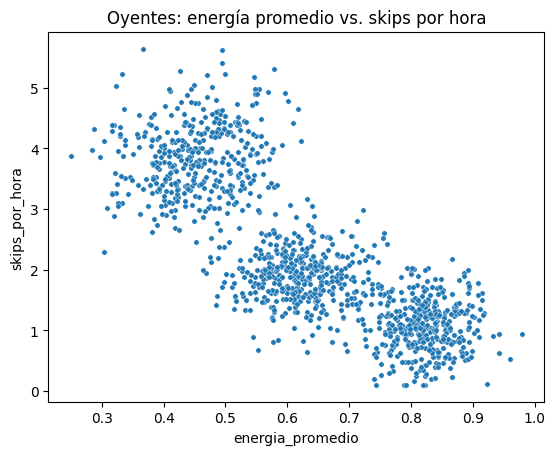

In [45]:
# Un gráfico de dispersión para intuir si hay grupos
sns.scatterplot(data=df, x="energia_promedio", y="skips_por_hora", s=15)
plt.title("Oyentes: energía promedio vs. skips por hora")
plt.show()


**Lectura:** a simple vista se intuyen **3 nubes de puntos**: mucha energía y pocos skips, poca energía
y muchos skips, y un grupo intermedio. K-Means nos dirá si esa intuición se confirma con las 4 variables.


## Bloque A2 · Construir `X` y escalar


* `X` = las 4 variables numéricas (quitamos `oyente_id`).
* K-Means usa **distancia euclidiana**: si una variable tiene números más grandes (`diversidad` va de 1 a 12)
  domina sobre otra con números pequeños (`energia_promedio` va de 0.25 a 0.98).
* `StandardScaler` lleva cada variable a **media 0 y desviación estándar 1**: z = (x − μ) / σ.
* `X_esc` se usa solo para **explorar** qué K conviene (Bloque A3).


In [46]:
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["oyente_id"])          # 4 variables numéricas

escalador = StandardScaler()
X_esc = escalador.fit_transform(X)          # media 0, desviación 1

print("Medias:", X_esc.mean(axis=0).round(2))
print("Desviaciones:", X_esc.std(axis=0).round(2))


Medias: [ 0.  0.  0. -0.]
Desviaciones: [1. 1. 1. 1.]


## Bloque A3 · Elegir K: método del codo + Silhouette


**Librerías nuevas:** `KMeans` (el algoritmo) y `silhouette_score` (la métrica).

Parámetros de `KMeans()` que usamos:

* `n_clusters=k` → número de grupos K.
* `n_init=10` → repite el algoritmo 10 veces con distintos centroides iniciales y se queda con el de **menor inercia**.
* `random_state=42` → semilla: el mismo resultado en cada ejecución.

Las dos métricas:

| Métrica | Rango | Qué buscamos |
| --- | --- | --- |
| Inercia (`inertia_`) | 0 a ∞ | El **codo**: el K a partir del cual la inercia casi deja de bajar |
| Silhouette | −1 a 1 | El K con el **valor más alto** (cercano a 1 = deseado) |

> `inertia_` es un **atributo**: no se pasa al crear el modelo, existe solo después de entrenar.
> Silhouette necesita al menos 2 clusters, por eso el bucle empieza en K = 2.


In [47]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

filas = []
for k in range(2, 10):                                  # K = 2 a 9
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km.fit_predict(X_esc)                   # cluster de cada oyente
    sil = silhouette_score(X_esc, etiquetas)
    filas.append([k, km.inertia_, sil])

resultados = pd.DataFrame(filas, columns=["K", "inercia", "silhouette"])
resultados.round(3)


,K,inercia,silhouette
0,2,1630.108,0.558
1,3,604.637,0.604
2,4,543.800,0.480
3,5,491.186,0.353
4,6,450.722,0.240
5,7,419.632,0.225
6,8,395.790,0.222
7,9,373.634,0.208


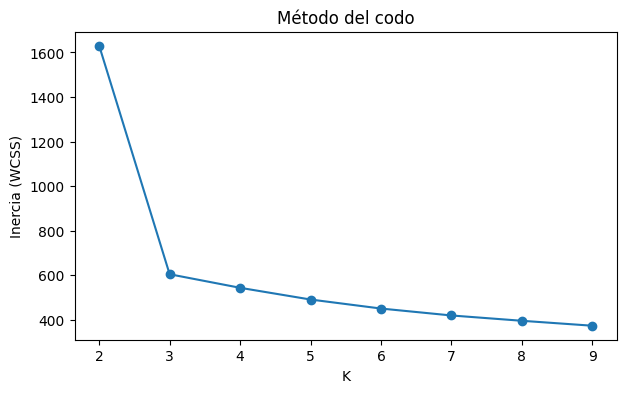

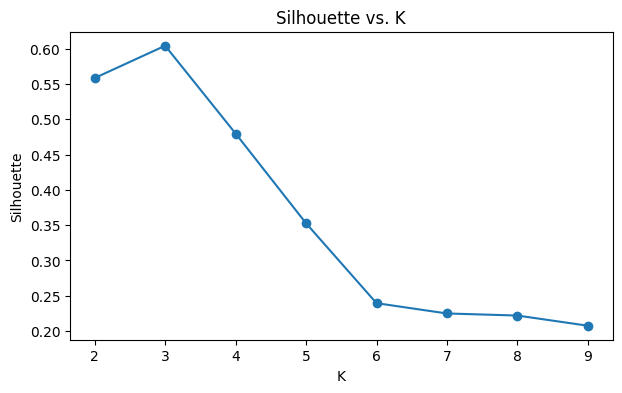

In [48]:
resultados.plot(x="K", y="inercia", marker="o", legend=False, figsize=(7, 4))
plt.title("Método del codo")
plt.ylabel("Inercia (WCSS)")
plt.show()

resultados.plot(x="K", y="silhouette", marker="o", legend=False, figsize=(7, 4))
plt.title("Silhouette vs. K")
plt.ylabel("Silhouette")
plt.show()


**Lectura:**

* **Codo:** de K = 2 a K = 3 la inercia baja de 1 630 a 605; de K = 3 a K = 4 solo baja 61 → codo en **K = 3**.
* **Silhouette:** el máximo es **0.604 en K = 3**, en el rango *bueno* (0.51 a 0.70). En K = 4 baja a 0.480 (*débil*).
* Las dos métricas coinciden: elegimos **K = 3**.


## Bloque A4 · Modelo con K = 3 dentro de un `Pipeline`


`Pipeline` (visto en clases anteriores) une el escalado y K-Means en un solo objeto:
se le pasa `X` **original** y escala por dentro. `fit_predict()` entrena y devuelve el cluster de cada fila.

> Los clusters salen numerados 0, 1 y 2. **El número no significa nada** (ni orden ni calidad):
> el nombre de cada perfil lo pondremos nosotros en el Bloque A5.


In [49]:
from sklearn.pipeline import Pipeline

modelo = Pipeline([("escalar", StandardScaler()),
                   ("kmeans", KMeans(n_clusters=3, n_init=10, random_state=42))])

df["cluster"] = modelo.fit_predict(X)          # X sin escalar: el Pipeline escala

print("Oyentes por cluster:")
print(df["cluster"].value_counts().sort_index())
print("Silhouette:", round(silhouette_score(X_esc, df["cluster"]), 3))


Oyentes por cluster:
cluster
0    400
1    399
2    401
Name: count, dtype: int64
Silhouette: 0.604


## Bloque A5 · Centroides e interpretación


`groupby("cluster").mean()` calcula el promedio de cada variable dentro de cada cluster:
son los **centroides en escala original** (horas, géneros…), fáciles de leer.
(`cluster_centers_` también los tiene, pero en escala estandarizada.)


In [50]:
columnas = list(X.columns)
centroides = df.groupby("cluster")[columnas].mean().round(2)
centroides


,horas_diarias,diversidad,energia_promedio,skips_por_hora
cluster,,,,
0,5.80,8.95,0.82,1.07
1,1.35,2.81,0.45,3.83
2,3.21,5.16,0.62,1.89


**Lectura y nombres propuestos (los pone el analista, no el algoritmo):**

| Cluster | horas\_diarias | diversidad | energia\_promedio | skips\_por\_hora | Perfil |
| --- | --- | --- | --- | --- | --- |
| 0 | 5.80 | 8.95 | 0.82 | 1.07 | **Intensivo**: muchas horas, muchos géneros, casi no salta canciones |
| 1 | 1.35 | 2.81 | 0.45 | 3.83 | **Casual**: pocas horas y salta muchas canciones |
| 2 | 3.21 | 5.16 | 0.62 | 1.89 | **Habitual**: perfil intermedio y estable |


## Bloque A6 · Mapa de los clusters


`sns.scatterplot(..., hue="cluster")` colorea cada oyente según su cluster. Dibujamos dos pares de variables.


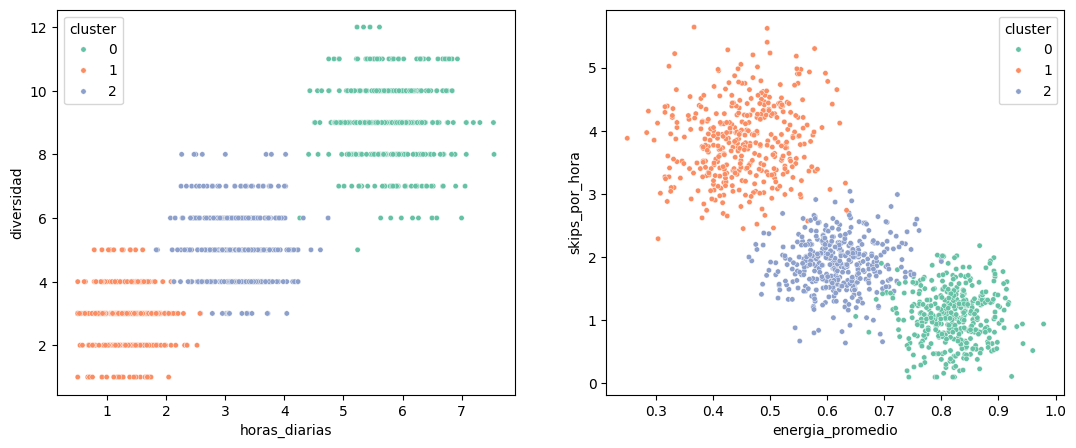

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="horas_diarias", y="diversidad", hue="cluster",
                palette="Set2", s=15, ax=axes[0])
sns.scatterplot(data=df, x="energia_promedio", y="skips_por_hora", hue="cluster",
                palette="Set2", s=15, ax=axes[1])
plt.show()


**Lectura:** los 3 grupos se separan con claridad y solo se tocan en los bordes:
por eso el Silhouette es bueno (0.604) y no excelente.


**Preguntas de la Parte A** (respóndelas en tu notebook):

1. ¿Qué perfil le interesaría más a Spotify para ofrecer una suscripción premium? ¿Por qué?

Para ofrecer una suscripcion premium le interesaria principalmente el perfil Habitual y el perfil Intensivo, con especial enfasis en el Habitual, dado que escucha musica de manera cotidiana tenidendo 3.21 horas diarias y salta 1.89 canciones por hora, por lo que las ventajas de saltos ilimitados y reproduccion sin anuncios representan un valor practico inmediato por el cual estaria dispuesto a pagar. Por su parte, el perfil Intensivo tambien es clave para asegurar alta retencion mediante calidad de audio superior y descargas sin conexion.

2. ¿Qué perfil tiene más riesgo de abandonar la plataforma? ¿Qué variable lo indica?

El perfil con mayor riesgo de abandono es el Casual. La variable que lo evidencia con mayor contundencia es skips por hora, con un promedio muy elevado de 3.83 saltos por hora, acompanado por un escaso tiempo de reproduccion de 1.35 horas diarias y muy baja diversidad siendo 2.81 generos, lo que refleja desinteres, frustracion con el contenido sugerido y falta de fidelizacion con la aplicacion.


# Parte B — Práctica Autónoma: Perfiles de Jugadores de Videojuegos en Ecuador


**Contexto:** una empresa de videojuegos quiere segmentar a sus 950 jugadores para diseñar campañas.
Repite el flujo de la Parte A con `jugadores_ecuador_B.csv`. En tu notebook, escribe el código que reemplace
cada `# TODO` de esta guía; las pistas en los comentarios indican qué función usar.

| Variable | Qué mide |
| --- | --- |
| `jugador_id` | Identificador: no entra en el modelo |
| `horas_semana` | Horas de juego por semana |
| `num_juegos_activos` | Juegos distintos activos en el mes |
| `tasa_victorias` | Proporción de partidas ganadas (0 a 1) |
| `gasto_mensual_usd` | Gasto mensual en compras dentro del juego (USD) |


## Bloque B1 · Carga, exploración y escalado


In [52]:
# TODO 1: carga jugadores_ecuador_B.csv en df_b y muestra df_b.describe().round(2)
df_b = pd.read_csv("jugadores_ecuador_B.csv")
print("Dimensiones de df_b:", df_b.shape)
display(df_b.describe().round(2))

# TODO 2: crea X_b quitando la columna jugador_id
X_b = df_b.drop(columns=["jugador_id"])

# TODO 3: escala X_b con StandardScaler y guarda el resultado en X_b_esc
#         pista: StandardScaler().fit_transform(X_b)
X_b_esc = StandardScaler().fit_transform(X_b)

print("Medias de X_b_esc:", X_b_esc.mean(axis=0).round(2))
print("Desviaciones de X_b_esc:", X_b_esc.std(axis=0).round(2))


Dimensiones de df_b: (950, 5)


,horas_semana,num_juegos_activos,tasa_victorias,gasto_mensual_usd
count,950.00,950.00,950.00,950.00
mean,12.48,3.60,0.52,12.14
std,7.46,2.36,0.13,18.77
min,1.00,1.00,0.21,0.00
25%,4.80,2.00,0.42,1.62
50%,11.15,2.00,0.49,5.38
75%,19.60,5.00,0.62,9.59
max,29.10,11.00,0.82,85.79


Medias de X_b_esc: [ 0. -0. -0. -0.]
Desviaciones de X_b_esc: [1. 1. 1. 1.]


**Pregunta:** según el análisis descriptivo, ¿qué variable tiene el rango más grande? ¿Por qué esa variable dominaría la distancia euclidiana si no escalamos?

La variable con el rango mas grande es gasto mensual usd, la cual va desde 0.00 hasta 85.79 USD con una desviacion estandar de 18.77, seguida por horas semana que alcanza hasta 29.10 horas. Si no se escala, la distancia euclidiana eleva al cuadrado las diferencias entre observaciones. Un ejemplo es que una diferencia de 30 o 50 dolares aporta valores cuadraticos de 900 a 2500 a la suma total, mientras que una variable como tasa victorias que solo varia entre 0.21 y 0.82 aporta como maximo diferencias cuadraticas de 0.37. De esta manera, el gasto en dinero dominaria casi por completo el calculo de distancias, haciendo invisibles las diferencias en el desempeno y tiempo de juego.


## Bloque B2 · Elegir K


,K,inercia,silhouette
0,2,2158.296,0.457
1,3,1274.051,0.565
2,4,508.535,0.657
3,5,458.587,0.554
4,6,411.541,0.479
5,7,368.994,0.436
6,8,329.315,0.312
7,9,305.999,0.310


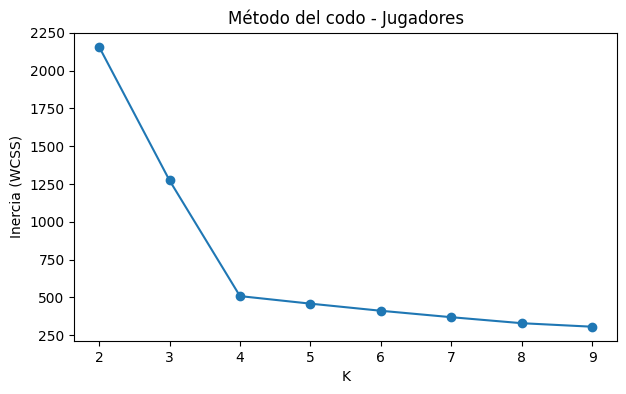

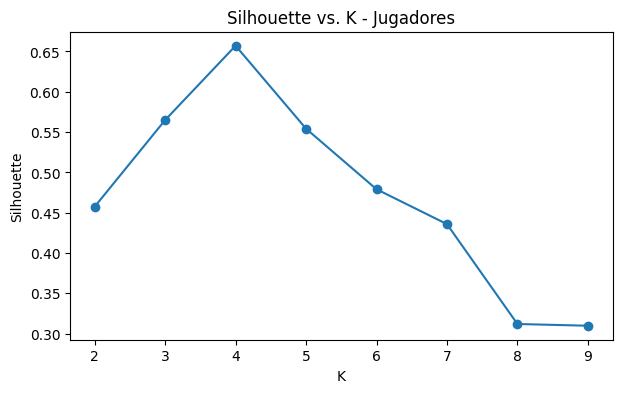

In [53]:
# TODO 4: con un bucle for k in range(2, 10) entrena KMeans(n_clusters=k, n_init=10, random_state=42)
#         sobre X_b_esc y guarda K, inertia_ y silhouette_score en un DataFrame llamado resultados_b
#         pista: copia la estructura del Bloque A3
filas_b = []
for k in range(2, 10):
    km_b = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas_b = km_b.fit_predict(X_b_esc)
    sil_b = silhouette_score(X_b_esc, etiquetas_b)
    filas_b.append([k, km_b.inertia_, sil_b])

resultados_b = pd.DataFrame(filas_b, columns=["K", "inercia", "silhouette"])
display(resultados_b.round(3))

# TODO 5: grafica el codo y el Silhouette con resultados_b.plot(x="K", y=..., marker="o")
resultados_b.plot(x="K", y="inercia", marker="o", legend=False, figsize=(7, 4))
plt.title("Método del codo - Jugadores")
plt.ylabel("Inercia (WCSS)")
plt.show()

resultados_b.plot(x="K", y="silhouette", marker="o", legend=False, figsize=(7, 4))
plt.title("Silhouette vs. K - Jugadores")
plt.ylabel("Silhouette")
plt.show()


**Preguntas:**

1. ¿En qué K está el codo? ¿En qué K está el máximo de Silhouette? ¿Coinciden?

El codo se encuentra nitidamente en K = 4, donde la inercia experimenta un descenso desde 1274.05 hasta 508.54 y luego se aplana con reducciones minimas hacia K = 5. Asimismo, el maximo coeficiente de Silhouette se ubica con precision en K = 4 con un puntaje de 0.657. Ambas tecnicas coinciden de forma contundente en K = 4.

2. ¿En qué rango de interpretación (excelente, bueno, débil…) queda el Silhouette del K que eliges? ¿Es mejor o peor que el de la Parte A?

El Silhouette de 0.657 obtenido en K = 4 se ubica dentro del rango de interpretacion calificado como bueno que va desde 0.51 y 0.70, indicando conglomerados compactos y bien diferenciados. Este resultado es superior al obtenido en la Parte A con los oyentes de Spotify que fue de 0.604, lo que demuestra una separacion estructural mas limpia entre los perfiles de jugadores.


## Bloque B3 · Modelo final y centroides


In [54]:
# TODO 6: crea modelo_b = Pipeline con ("escalar", StandardScaler()) y ("kmeans", KMeans(...))
#         usando el K que elegiste, y guarda df_b["cluster"] = modelo_b.fit_predict(X_b)
modelo_b = Pipeline([("escalar", StandardScaler()),
                     ("kmeans", KMeans(n_clusters=4, n_init=10, random_state=42))])

df_b["cluster"] = modelo_b.fit_predict(X_b)

print("Jugadores por cluster:")
print(df_b["cluster"].value_counts().sort_index())
print("Silhouette con K=4:", round(silhouette_score(X_b_esc, df_b["cluster"]), 3))

# TODO 7: calcula los centroides en escala original con
#         df_b.groupby("cluster")[list(X_b.columns)].mean().round(2)
centroides_b = df_b.groupby("cluster")[list(X_b.columns)].mean().round(2)
display(centroides_b)


Jugadores por cluster:
cluster
0    280
1    247
2    139
3    284
Name: count, dtype: int64
Silhouette con K=4: 0.657


,horas_semana,num_juegos_activos,tasa_victorias,gasto_mensual_usd
cluster,,,,
0,22.05,2.01,0.68,7.92
1,10.02,7.11,0.47,5.32
2,14.98,3.97,0.52,55.15
3,3.96,1.94,0.40,1.19


**Completa la tabla en tu notebook** con tus centroides y un nombre para cada perfil:

| Cluster | horas_semana | num_juegos_activos | tasa_victorias | gasto_mensual_usd | Perfil propuesto |
| --- | --- | --- | --- | --- | --- |
| 0 | 22.05 | 2.01 | 0.68 | 7.92 | Competitivo: muchas horas, alta tasa de victorias y pocos juegos |
| 1 | 10.02 | 7.11 | 0.47 | 5.32 | Diverso: muchas horas repartidas en numerosos titulos |
| 2 | 14.98 | 3.97 | 0.52 | 55.15 |Gran Pagador: horas moderadas pero gasto mensual sumamente alto |
| 3 | 3.96 | 1.94 | 0.40 | 1.19 | Ocasional: muy pocas horas a la semana y gasto casi inexistente |


**Pregunta:** ¿hay algún grupo con horas de juego moderadas pero gasto muy alto? ¿Qué nombre le darías y qué campaña le ofrecerías?

Si, se trata exactamente del Cluster 2, cuyos jugadores dedican 14.98 horas semanales pero registran un gasto promedio extraordinario de 55.15 USD mensuales, superando en mas de siete veces al resto de grupos. El nombre que le daría es Gran Pagador. La campana recomendada es un programa de membresia VIP con atencion preferencial, acceso anticipado exclusivo a paquetes esteticos de coleccion, pases de batalla de edicion de lujo y ofertas con valor anadido que recompensen su fidelidad monetaria sin exigirles una cantidad abrumadora de tiempo en juego.


## Bloque B4 · Mapa de los clusters


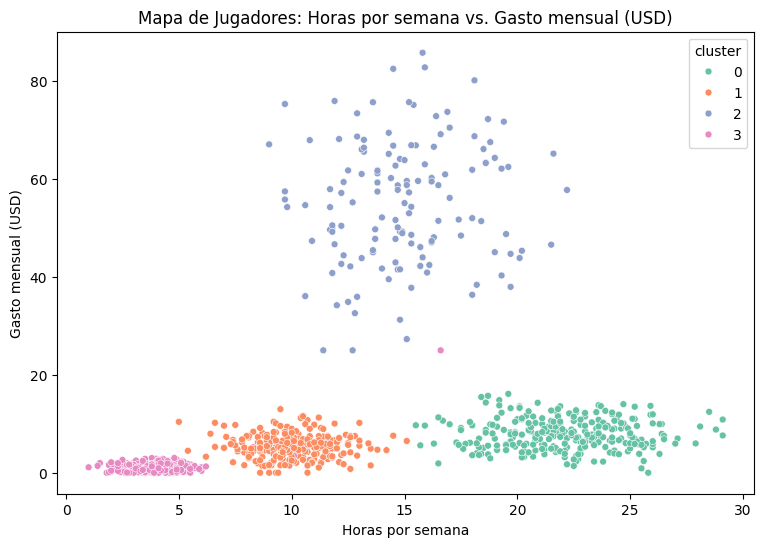

In [55]:
# TODO 8: dibuja con sns.scatterplot(data=df_b, x="horas_semana", y="gasto_mensual_usd", hue="cluster")
#         el mapa de los jugadores coloreados por cluster
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_b, x="horas_semana", y="gasto_mensual_usd", hue="cluster",
                palette="Set2", s=25)
plt.title("Mapa de Jugadores: Horas por semana vs. Gasto mensual (USD)")
plt.xlabel("Horas por semana")
plt.ylabel("Gasto mensual (USD)")
plt.show()


**Pregunta:** ¿qué variable separa mejor al grupo de mayor gasto del resto? ¿Cómo lo ves en el gráfico?

Esa variable es gasto mensual usd, en el grafico de dispersion se aprecia como todos los puntos del Cluster 2 forman una franja horizontal netamente diferenciada por encima de los 35 USD y hasta superar los 80 USD, mientras que la totalidad de los jugadores de los otros tres clusters se concentran aglomerados en la franja baja inferior por debajo de los 15 USD.


## Bloque B5 · ¿Qué pasa si no escalamos?


Entrena el mismo K-Means **sin** `StandardScaler` (directamente sobre `X_b`) y compara sus centroides con los del Bloque B3.


In [56]:
# Bloque B5: Entrenamiento sin escalar para comparación de efectos en K-Means
from sklearn.cluster import KMeans

km_sin_escalar = KMeans(n_clusters=4, n_init=10, random_state=42)
df_b["cluster_sin_escalar"] = km_sin_escalar.fit_predict(X_b)

print(f"Inercia sin escalar (K=4): {km_sin_escalar.inertia_:.2f}")
print("\nJugadores por cluster sin escalar:")
print(df_b["cluster_sin_escalar"].value_counts().sort_index())

print("\nCentroides sin escalar (escala original):")
centroides_sin_escalar = df_b.groupby("cluster_sin_escalar")[list(X_b.columns)].mean().round(2)
display(centroides_sin_escalar)

Inercia sin escalar (K=4): 26793.20

Jugadores por cluster sin escalar:
cluster_sin_escalar
0    285
1     69
2    528
3     68
Name: count, dtype: int64

Centroides sin escalar (escala original):


,horas_semana,num_juegos_activos,tasa_victorias,gasto_mensual_usd
cluster_sin_escalar,,,,
0,21.91,2.06,0.68,8.10
1,15.16,4.00,0.52,65.62
2,6.73,4.34,0.43,3.06
3,14.88,3.96,0.52,45.42


**Preguntas de reflexión:**

1. Sin escalar, ¿qué variable decide casi sola los grupos? ¿Qué perfiles del Bloque B3 se pierden o se mezclan?

Sin estandarizar, la variable gasto mensual usd decide casi de manera exclusiva la particion de los clusters, agrupando a los jugadores simplemente en cuatro niveles de dinero. En este proceso se pierden y mezclan totalmente los perfiles de Explorador que dependia de num juegos activos = 7.11 y Competitivo que dependia de tasa victorias = 0.68, pues dichas variables quedan reducidas a ruido insignificante comparadas con la escala monetaria.

2. ¿Qué limitación de K-Means observaste en este dataset?

Pude notar la vulnerabilidad de K-Means frente a la escala de las variables debido al calculo geometrico de distancias euclidianas, requiriendo obligatoriamente un escalador como StandardScaler. Tambien vi que K-Means tiende a forzar divisiones de igual tamaño y morfologia esferica, lo que provoca segmentaciones artificiales en variables asimetricas si no se comprende el contexto del negocio.

3. La empresa quiere aumentar sus ingresos: ¿a qué cluster dirigiría su campaña y por qué?

La empresa deberia orientar sus esfuerzos comerciales en dos direcciones estrategicas: en primer lugar, blindar al grupoo de Grandes Pagadores mediante beneficios VIP exclusivos porque representan el mayor volumen de facturacion. Por otro lado, desplegar campanas de monetizacion para el grupo de Competitivos, dado que los jugadores competitivos dedican mas de 22 horas semanales y tienen un alto compromiso con el juego pero actualmente solo gastan 7.92 USD, por lo que podrian ofrecer pases de batalla a costos accesibles o articulos competitivos exclusivos para elevar los ingresos globales.


# Bloque C — Entrenamiento Final, Exportación y Uso con Oyentes Nuevos


**Idea central:** en clustering no hay división train/test, así que el análisis de la Parte A ya usó el 100% de los oyentes.
El **modelo final** repite ese ajuste con los 1 200 oyentes, se guarda en un archivo y se usa para asignar un
perfil a oyentes nuevos **sin volver a entrenar**.


## Bloque C1 · Reentrenar con el 100% de los datos


* **Análisis (exploración):** el bucle de K y `modelo` sirvieron para elegir K = 3 y nombrar los perfiles.
* **Modelo final (100%):** `modelo_final` = escalar + KMeans, listo para datos nuevos.
* Con la misma semilla (`random_state=42`) los números de cluster coinciden con los del Bloque A5:
  verifícalo con los centroides antes de fijar el diccionario `perfiles`.


In [57]:
modelo_final = Pipeline([("escalar", StandardScaler()),
                         ("kmeans", KMeans(n_clusters=3, n_init=10, random_state=42))])
modelo_final.fit(X)                                  # 100%: los 1 200 oyentes

perfiles = {0: "Intensivo", 1: "Casual", 2: "Habitual"}
print("Centroides del modelo final (escala original):")
print(X.groupby(modelo_final.predict(X)).mean().round(2))     # compara con el Bloque A5


Centroides del modelo final (escala original):
   horas_diarias  diversidad  energia_promedio  skips_por_hora
0           5.80        8.95              0.82            1.07
1           1.35        2.81              0.45            3.83
2           3.21        5.16              0.62            1.89


## Bloque C2 · Exportar el modelo con `joblib`


Guardamos en un solo archivo `.pkl` el **Pipeline entrenado** (medias, desviaciones y centroides)
junto con el diccionario de **perfiles**.

> Carga el `.pkl` con la **misma versión de scikit-learn** con la que se guardó.


In [58]:
import joblib

joblib.dump({"modelo": modelo_final, "perfiles": perfiles}, "modelo_kmeans_spotify.pkl")
print("Modelo exportado a modelo_kmeans_spotify.pkl")


Modelo exportado a modelo_kmeans_spotify.pkl


## Bloque C3 · Usar el modelo con oyentes nuevos


Así se usaría el archivo **desde otro programa** (por ejemplo, un servicio web que recibe los datos de un oyente).
El DataFrame lleva las **mismas 4 columnas** de `X`, con los mismos nombres y **sin escalar**:
`predict()` escala con las medias aprendidas y asigna el centroide más cercano.


In [59]:
import joblib
import pandas as pd

paquete = joblib.load("modelo_kmeans_spotify.pkl")
modelo_cargado, perfiles = paquete["modelo"], paquete["perfiles"]

nuevos = pd.DataFrame({
    "horas_diarias":    [6.2, 1.0, 3.0],
    "diversidad":       [10, 2, 5],
    "energia_promedio": [0.85, 0.40, 0.60],
    "skips_por_hora":   [0.8, 4.5, 2.0]},
    index=["Oyente A", "Oyente B", "Oyente C"])

nuevos["cluster"] = modelo_cargado.predict(nuevos)
nuevos["perfil"] = nuevos["cluster"].map(perfiles)
nuevos


,horas_diarias,diversidad,energia_promedio,skips_por_hora,cluster,perfil
Oyente A,6.2,10,0.85,0.8,0,Intensivo
Oyente B,1.0,2,0.40,4.5,1,Casual
Oyente C,3.0,5,0.60,2.0,2,Habitual


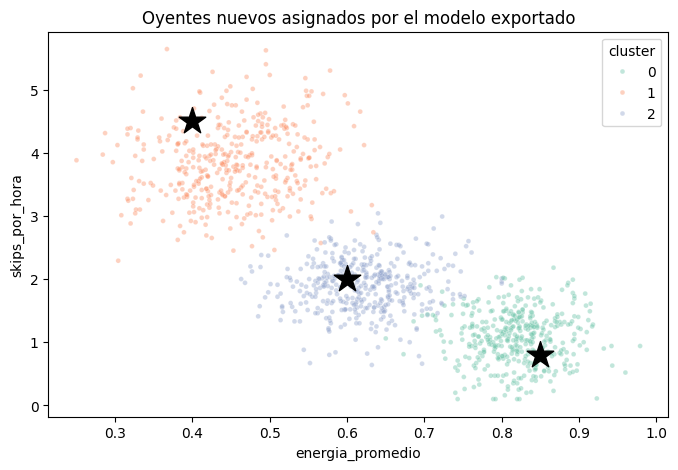

In [60]:
# Los oyentes nuevos (estrellas) sobre el mapa de la Parte A
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="energia_promedio", y="skips_por_hora", hue="cluster",
                palette="Set2", s=12, alpha=0.4)
plt.scatter(nuevos["energia_promedio"], nuevos["skips_por_hora"], marker="*", s=400, color="black")
plt.title("Oyentes nuevos asignados por el modelo exportado")
plt.show()


**Lectura:**

* **Oyente A** (6.2 h, 10 géneros, mucha energía, pocos skips) → cluster 0 → **Intensivo**.
* **Oyente B** (1 h, 2 géneros, poca energía, muchos skips) → cluster 1 → **Casual**.
* **Oyente C** (valores intermedios) → cluster 2 → **Habitual**.
* No se volvió a entrenar nada: se usaron las medias y los centroides aprendidos con los 1 200 oyentes.


## Conclusiones


* K-Means es **no supervisado**: agrupa observaciones parecidas sin usar ninguna `y`.
* Siempre se **escala** antes: la distancia euclidiana premia a la variable con números más grandes.
* **K** se elige con el **codo** (inercia) y el **máximo de Silhouette**; cuando coinciden, la elección es sólida.
* Los **centroides en escala original** permiten nombrar cada perfil; el nombre lo pone el analista.
* El modelo final se entrena con el 100%, se exporta con `joblib` y asigna perfiles a datos nuevos con `predict()`.
